(user_guide_optimization_de)=

# Differential Evolution (DE)

📖 {ref}`Differential Evolution API Reference <api_optimization_DE>`

**Differential Evolution (DE)** (Storn & Price, 1997) is an evolutionary algorithm for continuous optimization. Like a [genetic algorithm](bga.ipynb), it maintains a population of candidates and improves it through mutation, crossover and selection. What makes DE special is how it mutates: it perturbs candidates with *scaled differences of other members of the population*. Early on the population is spread out, so these differences are large and the search explores. As it converges, the differences shrink and the steps become small. This way, the step size adapts to the landscape automatically, without any explicit step-size parameter.

The implementation, {py:class}`~sigmaepsilon.math.optimize.de.DifferentialEvolution`, follows the same usage pattern as the [genetic algorithms](bga.ipynb), [ACO](aco.ipynb) and [PSO](pso.ipynb) of the library, and can also return **several distinct solutions**, one per basin of attraction.

## How it works

In every iteration, a *trial vector* $\mathbf{u}_i$ is built for every member $\mathbf{x}_i$ of the population in three steps.

**1. Mutation.** A *mutant* $\mathbf{v}_i$ is built from other members. With the classic `"rand/1/bin"` strategy, three distinct members $\mathbf{x}_{r_1}, \mathbf{x}_{r_2}, \mathbf{x}_{r_3}$, all different from $\mathbf{x}_i$, are picked at random, and

$$
\mathbf{v}_i = \mathbf{x}_{r_1} + F\,(\mathbf{x}_{r_2} - \mathbf{x}_{r_3}),
$$

where $F$ is the *differential weight*. Two greedier strategies are available via `strategy`. Both use the best member $\mathbf{x}_{best}$ of the population:

* `"best/1/bin"`: $\mathbf{v}_i = \mathbf{x}_{best} + F\,(\mathbf{x}_{r_1} - \mathbf{x}_{r_2})$
* `"current-to-best/1/bin"`: $\mathbf{v}_i = \mathbf{x}_i + F\,(\mathbf{x}_{best} - \mathbf{x}_i) + F\,(\mathbf{x}_{r_1} - \mathbf{x}_{r_2})$

They usually converge faster, at a higher risk of converging prematurely to a local optimum.

**2. Crossover.** The trial vector takes every coordinate from the mutant with probability $CR$, and from $\mathbf{x}_i$ otherwise (*binomial* crossover):

$$
u_{i,j} =
\begin{cases}
v_{i,j} & \text{if } r_j < CR \text{ or } j = j_{rand}, \\
x_{i,j} & \text{otherwise,}
\end{cases}
$$

where $j_{rand}$ is a random coordinate. It guarantees that the trial differs from $\mathbf{x}_i$ in at least one coordinate. Coordinates that end up outside `ranges` are moved back onto the boundary.

**3. Selection.** The trial is evaluated, and it replaces $\mathbf{x}_i$ if it is better. The population never gets worse, so the best member is always kept, with no extra elitism mechanism.

The hyperparameters, with their defaults:

| parameter | default | meaning |
|---|---|---|
| `nPop` | 40 | size of the population (at least 4) |
| `F` | 0.8 | differential weight, typically in $[0.4, 1]$; larger values explore more |
| `CR` | 0.9 | crossover probability; low values suit separable problems, high values problems with interacting variables |
| `strategy` | `"rand/1/bin"` | mutation strategy |

The stopping rules are the same as for the other optimizers: `maxiter`, `miniter`, and `maxage` / `ftol` for stagnation of the champion.

## When to use it (and when not to)

DE is a good fit for **continuous, box-bounded** black-box problems, and it is particularly robust on rugged, multimodal or ill-conditioned landscapes. It is one of the most reliable general-purpose metaheuristics for real-valued variables, and it has few parameters.

It is usually **not** the right tool for linear problems ([Linear Programming](lp.ipynb)), smooth problems with available gradients (gradient-based solvers), or discrete and combinatorial problems ([integer GA](ga_variants.ipynb), [ACO](aco.ipynb)). [PSO](pso.ipynb) covers the same ground and is worth comparing against.

## Basic usage

The usage is the same as for PSO. Let's minimize the Rosenbrock function, whose minimum is at $(1, 1)$. Remember that the optimizers **maximize by default**.

In [1]:
import numpy as np
from sigmaepsilon.math.optimize import DifferentialEvolution as DE


def rosenbrock(x, a=1.0, b=100.0):
    return (a - x[0]) ** 2 + b * (x[1] - x[0] ** 2) ** 2


ranges = [[-5, 5], [-5, 5]]

de = DE(rosenbrock, ranges, minimize=True, seed=0)
champion = de.solve()
champion.phenotype, champion.fitness

([1.0000002372535732, 1.0000004873426944], 7.276424236620201e-14)

In [2]:
de.state.to_scipy()

   message: 
   success: True
    status: 2
       fun: 7.276424236620201e-14
         x: [ 1.000e+00  1.000e+00]
       nit: 117
 diversity: 2.122540135307391e-06
      nfev: 4720
      njev: 0
      nhev: 0

Like the other optimizers, DE accepts `vectorized=True` for objectives that evaluate a `(nPop, dim)` batch at once, `n_jobs` for parallel evaluation, symbolic {py:class}`~sigmaepsilon.math.function.function.Function` objectives, and `evolve(cycles)` for driving the iterations by hand. You can also change hyperparameters between runs through `solve` or `set_solution_params`.

### Comparing the strategies

Let's compare the three strategies over 10 seeds each on two problems: Rosenbrock, which is unimodal, and the 5-dimensional Rastrigin function, which has a huge number of local minima and its global minimum of 0 at the origin. We run every strategy with the default `CR=0.9` and with `CR=0.2`:

In [3]:
def rastrigin(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))


problems = {
    "Rosenbrock (2d)": (rosenbrock, ranges),
    "Rastrigin (5d)": (rastrigin, [[-5.12, 5.12]] * 5),
}
print(f"{'problem':<17}{'CR':>4}  {'strategy':<23}{'mean best':>11}{'worst':>11}{'mean nfev':>11}")
for name, (fnc, bounds) in problems.items():
    for CR in [0.9, 0.2]:
        for strategy in DE.strategies:
            best, nfev = [], []
            for seed in range(10):
                de = DE(fnc, bounds, minimize=True, strategy=strategy, CR=CR, maxage=50, maxiter=500, seed=seed)
                best.append(de.solve().fitness)
                nfev.append(de.state.n_fev)
            print(f"{name:<17}{CR:>4}  {strategy:<23}{np.mean(best):>11.2e}{np.max(best):>11.2e}{np.mean(nfev):>11.0f}")

problem            CR  strategy                 mean best      worst  mean nfev


Rosenbrock (2d)   0.9  rand/1/bin                2.09e-17   6.15e-17       5644


Rosenbrock (2d)   0.9  best/1/bin                1.43e-21   6.99e-21       3932


Rosenbrock (2d)   0.9  current-to-best/1/bin     3.95e-20   1.70e-19       4280


Rosenbrock (2d)   0.2  rand/1/bin                4.97e-03   3.61e-02       7916


Rosenbrock (2d)   0.2  best/1/bin                1.67e-05   1.67e-04       7792


... (3 outputs left out)

Rastrigin (5d)    0.9  current-to-best/1/bin     6.89e+00   1.31e+01       4368


Rastrigin (5d)    0.2  rand/1/bin                3.17e-13   1.53e-12      12468


Rastrigin (5d)    0.2  best/1/bin                1.99e-01   9.95e-01       8736


Rastrigin (5d)    0.2  current-to-best/1/bin     5.48e-01   2.11e+00      15324


A few lessons from the table:

* On **Rosenbrock** with the default `CR=0.9`, every strategy finds the minimum. The greedy strategies get there with fewer evaluations, because they exploit the best member directly. With `CR=0.2`, the results are clearly worse: the variables of Rosenbrock interact (the valley is curved), so good trial vectors must change several coordinates at once.
* On **Rastrigin** with `CR=0.9`, no setting finds the global minimum reliably: the runs stagnate in one of the many local minima.
* Rastrigin, on the other hand, is *separable*: it is a sum of 1d functions, one per variable. A low `CR` changes only one or two coordinates per trial, which suits such problems. With `CR=0.2`, `"rand/1/bin"` finds the global minimum in every run. It needs more evaluations to do so, and the greedy strategies still get stuck now and then.

As usual for metaheuristics, there is no single best setting. The default `"rand/1/bin"` is the safest choice. A low `CR` is worth trying if the variables are (nearly) independent, and the greedy strategies are worth trying when evaluations are expensive and the landscape is known to be benign.

## Multiple solutions

Set `n_solutions` to the number of distinct optima you are interested in. With `n_solutions > 1`, DE switches to the *neighborhood-based crowding DE* of Qu, Suganthan & Liang (2012), which differs from plain DE in two ways:

* **crowding selection** (Thomsen, 2004): a trial vector doesn't compete with its parent but with the member of the population *closest* to it. A good trial in one basin can therefore only replace a member of the same basin, and the population can't collapse into the single most attractive basin.
* **neighborhood mutation**: the members used to build a mutant are drawn from the `n_neighbors` (default 5) nearest neighbours of $\mathbf{x}_i$, not from the whole population. The difference vectors stay small and local, so every niche converges quickly to its own optimum instead of being perturbed by vectors that span different basins.

The greedy strategies would pull everything towards the best member, so they are incompatible with this mode. If you combine them with `n_solutions > 1`, DE warns and uses `"rand/1/bin"`.

The final solutions are extracted by the `solutions` property, exactly as for {ref}`PSO <user_guide_optimization_pso_multiple>`. Members are visited from best to worst, and a point is accepted only if it is farther than `niche_radius` from every accepted point **and** the hill-valley test finds a barrier between it and each of them. This guarantees that **every optimum is returned only once**, and the first solution is always the champion.

On Himmelblau's function, with its four equal minima:

In [4]:
import matplotlib.pyplot as plt


def himmelblau(x):
    return (x[0] ** 2 + x[1] - 11) ** 2 + (x[0] + x[1] ** 2 - 7) ** 2


de = DE(himmelblau, ranges, nPop=60, minimize=True, n_solutions=4, seed=0)
de.solve()
[(np.round(s.phenotype, 4).tolist(), s.fitness) for s in de.solutions]

[([-2.8051, 3.1313], 1.500971647600686e-15),
 ([3.0, 2.0], 3.663039778186304e-14),
 ([3.5844, -1.8481], 8.383593388426172e-14),
 ([-3.7793, -3.2832], 9.855049846979197e-09)]

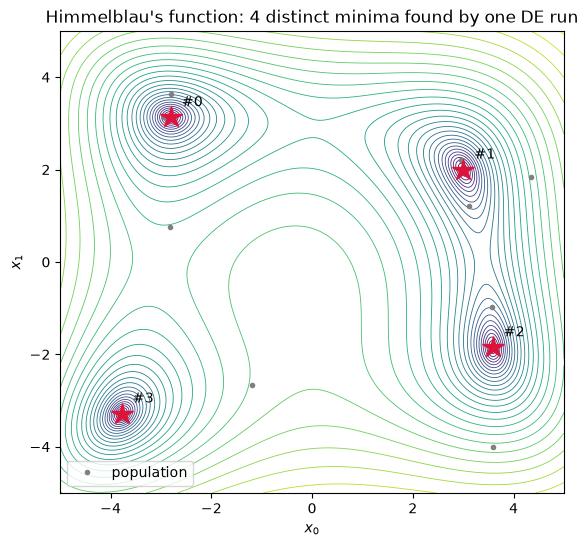

In [5]:
X, Y = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-5, 5, 300))
Z = himmelblau([X, Y])

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.contour(X, Y, np.log1p(Z), levels=30, cmap="viridis", linewidths=0.6)
ax.plot(*de.phenotypes.T, ".", color="gray", label="population")
for i, s in enumerate(de.solutions):
    ax.plot(*s.phenotype, "*", color="crimson", ms=16)
    ax.annotate(f"#{i}", s.phenotype, textcoords="offset points", xytext=(8, 8))
ax.set_xlabel("$x_0$")
ax.set_ylabel("$x_1$")
ax.set_title("Himmelblau's function: 4 distinct minima found by one DE run")
ax.legend(loc="lower left");

The solutions don't have to be equally good. The function below has five local minima inside $[-5, 5]$ with very different values, and we ask for up to 10 solutions:

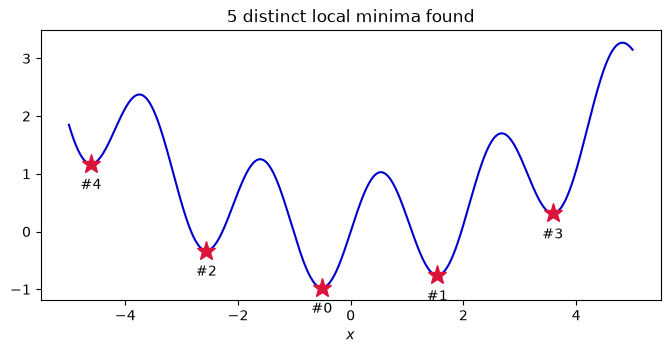

In [6]:
def wavy(x):
    return np.sin(3 * x[0]) + 0.1 * x[0] ** 2


de = DE(wavy, [[-5, 5]], minimize=True, n_solutions=10, seed=0)
de.solve()

t = np.linspace(-5, 5, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t, wavy([t]), color="mediumblue")
for i, s in enumerate(de.solutions):
    ax.plot(s.phenotype[0], s.fitness, "*", color="crimson", ms=14)
    ax.annotate(f"#{i}", (s.phenotype[0], s.fitness), textcoords="offset points", xytext=(0, -18), ha="center")
ax.set_xlabel("$x$")
ax.set_title(f"{len(de.solutions)} distinct local minima found");

All five interior minima are found and ranked by their value, from the global minimum (#0) to the shallow one at the left end (#4). We get five solutions rather than the 10 we asked for: no duplicates are added to fill up the list.

Note that the segment between two distant minima, e.g. #3 and #4, crosses all the other basins. If only a few points of it were tested, they could all land in deeper valleys and miss the hills between. To prevent this, the hill-valley test places its points at most `niche_radius / 2` apart along the segment.

The function also decreases towards $x = 5$, so the right end of the interval is a sixth, boundary minimum with a tiny basin. No member settled there, so it isn't found. Small basins can be missed, and a larger `nPop` makes that less likely.

The practical notes of the {ref}`PSO page <user_guide_optimization_pso_multiple>` apply here as well:

* the run only stops early once no member of the population improves anymore,
* plan for roughly 10–15 members per expected optimum,
* the hill-valley tests are counted in `state.n_fev`.

## Constraints

Box constraints are handled by `ranges`. For general equality and inequality constraints, see {doc}`penalty`.